# Visualization Comparison and Accuracy Evaluation of Different Methods
## 1. Comparison Methods
- ILK-VG, OF-VG, INR-EST, INR-VG, ConstGS, AffineGS

## 2. Test Data
- Three synthetic event streams corresponding to different simulated flow fields;

In [1]:
# The basic funcs
import json
import os
import numpy as np
import pandas as pd
import torch
from tqdm.notebook import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt

from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

from methods import inr_vg,inr_est,of_vg,of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field,plot_event_time2d, create_colorbar
from utils.painter import plot_vortex_line_panel

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)              
torch.cuda.manual_seed(seed)         
torch.cuda.manual_seed_all(seed)    

# ====================== PyTorch ============================
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

CMax fused extension: OK
Using device: cuda
Using device: cuda


# Test Data

In [2]:
flow0 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")
flow1 = FlowManager(mode="data", data_path="./data/datasets/DNS_turbulence_00001_flow.npz")
flow2 = FlowManager(mode="data", data_path="./data/datasets/SQG_00001_flow.npz")
flow_names = ["JHTDB_isotropic", "DNS_turbulence", "SQG"]

In [4]:
def flow_metrics(div, omega_pred, omega_true):
    abs_div = np.abs(div)
    return {
        "mean_abs_div" : float(abs_div.mean()),
        "rmse_omega"   : float(np.sqrt(np.mean((omega_pred - omega_true) ** 2))),
    }

def build_wide_metrics_table(metrics_dict_list, flow_name_list=flow_names, method_order=None, round_digits=4):

    # 行顺序：六种方法
    if method_order is None:
        method_order = list(metrics_dict_list[0].keys())

    metrics_order = ["rmse", "aee", "mean|div|", "RMSE_ω"]

    # 构建二维数据
    data = {}
    for flow_name, metrics_dict in zip(flow_name_list, metrics_dict_list):
        for metric_name in metrics_order:
            col_key = (flow_name, metric_name)
            data[col_key] = [
                float(metrics_dict[method][metric_name]) if method in metrics_dict else float("nan")
                for method in method_order
            ]

    df = pd.DataFrame(data, index=method_order)
    df.index.name = "method"
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    df = df.round(round_digits)

    return df

# Methods

In [5]:
estimators = [ilk_vg, of_vg, inr_est, inr_vg, constGS, affineGS]
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]

def test(flow_index, coord_idx, H=256, W=256, error_map=True, plot_vor=True):

    flow_func = globals()[f"flow{flow_index}"].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 4.01
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05

    evts, (u, v) = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func).load()
    v_h_gt = u.squeeze().cpu().numpy()
    v_w_gt = v.squeeze().cpu().numpy()
    div_gt, vor_gt = compute_flow_quantities(v_h_gt, v_w_gt)

    vor_list = [vor_gt]   # 第0通道 = GT
    names = ["ground truth"]

    # 新增：用于保存各方法指标
    metrics_dict = {}

    for i, m in enumerate(estimators):
        
        v_h, v_w, div, vor = m(evts, H=H, W=W)
        rmse, aee = PIVmetric(v_h, v_w, v_h_gt, v_w_gt, show=False)[:2]
        # print(f"results：rmse: {rmse:.4f}、aee: {aee:.4f}")
        
        metric_vals = flow_metrics(div.detach().numpy(), vor.detach().numpy(), vor_gt.detach().numpy())
        # print(f"mean|div| : {metric_vals['mean_abs_div']:.4f}")
        # print(f"RMSE_ω    : {metric_vals['rmse_omega']:.4f}")

        # 新增：保存到字典
        metrics_dict[method_names[i]] = {
            "rmse": float(rmse),
            "aee": float(aee),
            "mean|div|": float(metric_vals["mean_abs_div"]),
            "RMSE_ω": float(metric_vals["rmse_omega"]),
        }

        names.append(method_names[i])
        vor_list.append(vor)
        
        if error_map:
            path = f"output/EXP2/on_single_flow/{flow_names[flow_index]}_{method_names[i]}.svg"

            plot_flow_field(v_h, v_w, v_h_gt, v_w_gt, output_file=None, magFlag=True, slFlag=False, colorbar_flag=False, step=1, quiver_step=32, 
                            v_min=0, v_max=0.5, scale=None, figsize=(2, 2), cbar_ticks=None, cbar_tick_size=12)

    vor_stack = torch.stack(vor_list, axis=0)   # [C, H, W]

    # 新增：返回指标字典
    return vor_stack, metrics_dict

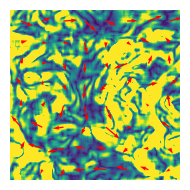

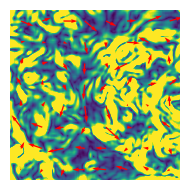

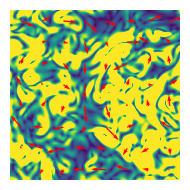

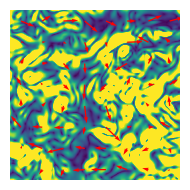

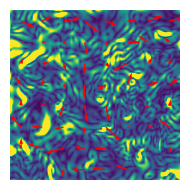

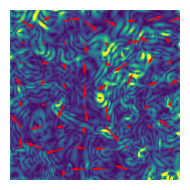

In [6]:
vor_stack0, metrics_dict0= test(flow_index = 0, coord_idx=128)
torch.cuda.empty_cache()

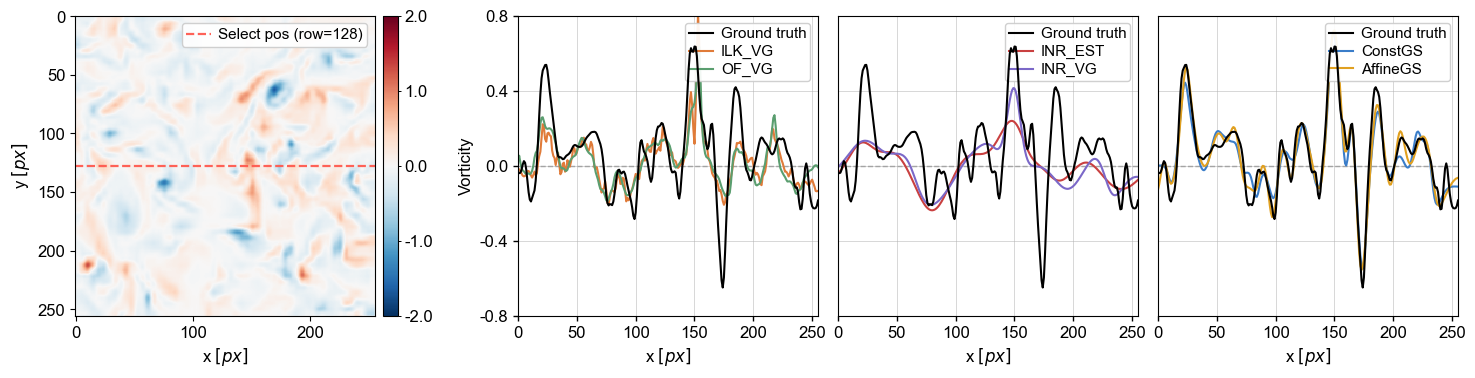

In [7]:
plot_vortex_line_panel(omega=vor_stack0, coord_idx=128, yticks=[-0.8, -0.4, 0, 0.4, 0.8], cbar_ticks=[-2, -1, 0, 1, 2], save_path="./output/fig10.pdf")

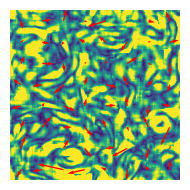

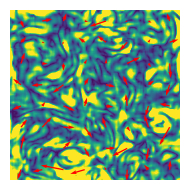

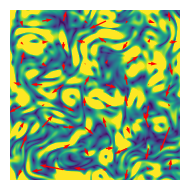

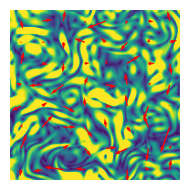

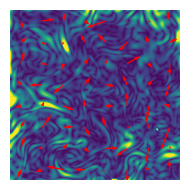

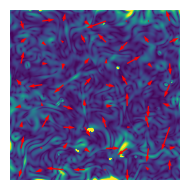

In [8]:
vor_stack1, metrics_dict1 = test(flow_index = 1, coord_idx=128)
torch.cuda.empty_cache()

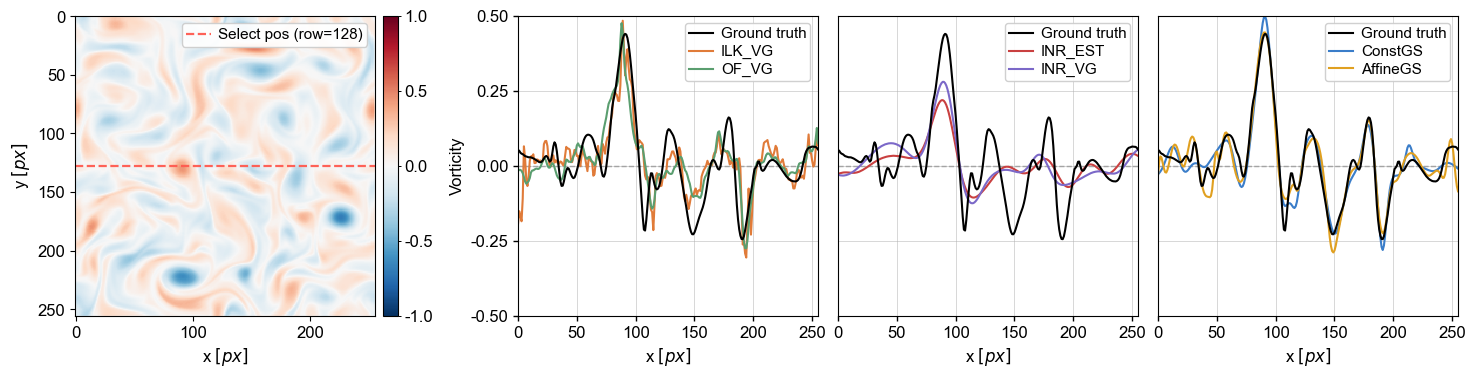

In [9]:
plot_vortex_line_panel(omega=vor_stack1, coord_idx=128, yticks=[-0.5, -0.25, 0, 0.25, 0.5], cbar_ticks=[-1, -0.5, 0, 0.5, 1], save_path=None)

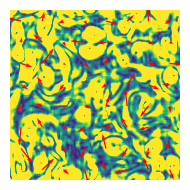

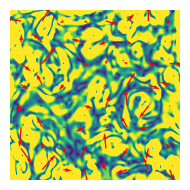

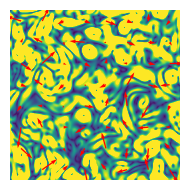

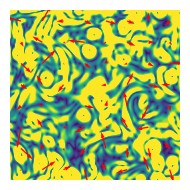

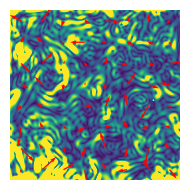

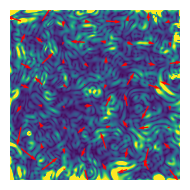

In [10]:
vor_stack2, metrics_dict2 = test(flow_index = 2, coord_idx=128)
torch.cuda.empty_cache()

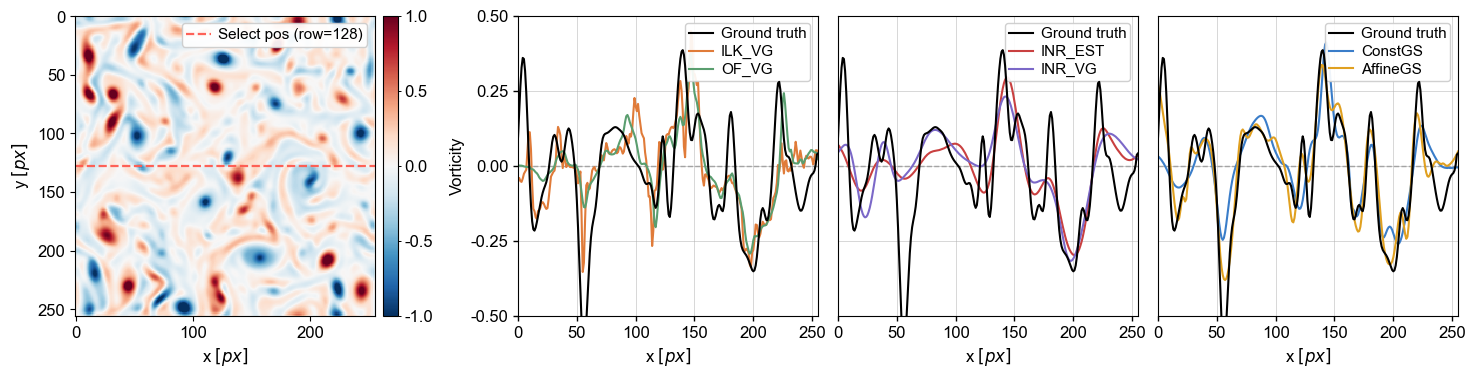

In [11]:
plot_vortex_line_panel(omega=vor_stack2, coord_idx=128, yticks=[-0.5, -0.25, 0, 0.25, 0.5], cbar_ticks=[-1, -0.5, 0, 0.5, 1], save_path=None)

In [12]:
build_wide_metrics_table(metrics_dict_list=[metrics_dict0, metrics_dict1, metrics_dict2],
    flow_name_list=flow_names, method_order=method_names, round_digits=4)

JHTDB_isotropic                           DNS_turbulence          \
                    rmse     aee mean|div|  RMSE_ω           rmse     aee   
method                                                                      
ILK_VG            0.6116  0.4538    0.0367  0.1437         0.4056  0.3407   
OF_VG             0.5472  0.4162    0.0317  0.1415         0.3574  0.2935   
INR_EST           0.6571  0.5010    0.0173  0.1535         0.4153  0.3525   
INR_VG            0.5599  0.4222    0.0172  0.1405         0.3682  0.3157   
ConstGS           0.2443  0.1925    0.0097  0.0858         0.1513  0.1204   
AffineGS          0.1601  0.1263    0.0053  0.0678         0.1272  0.0971   

                               SQG                            
         mean|div|  RMSE_ω    rmse     aee mean|div|  RMSE_ω  
method                                                        
ILK_VG      0.0334  0.0932  0.7343  0.5445    0.0442  0.2255  
OF_VG       0.0280  0.0827  0.6702  0.5209    0.0383  0.1675  
INR_EST     0.0138  0.0877  0.5827  0.4680    0.0283  0.1564  
INR_VG      0.0125  0.0832  0.6140  0.4952    0.0250  0.1664  
ConstGS     0.0056  0.0485  0.3722  0.2698    0.0170  0.1161  
AffineGS    0.0053  0.0612  0.2229  0.1655    0.0092  0.0951

Colorbar saved to ./output/EXP2/on_single_flow/JHTDB_isotropic.svg


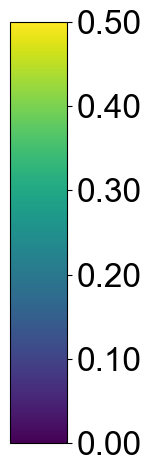

In [13]:
# for flow_index in range(len(flow_names)):
for flow_index in range(1):
    colorbar_path = f"./output/EXP2/on_single_flow/{flow_names[flow_index]}.svg"
    create_colorbar(0, 0.5, figsize=(1.6, 4.8), fontsize=24, orientation='vertical', 
                    output_file=colorbar_path, label=None)

## Datasets

In [4]:
def save_results_to_json(results, save_path, indent=1):
    def convert_numpy_types(obj):
        if isinstance(obj, (np.integer, np.floating)): 
            return obj.item()
        elif isinstance(obj, np.ndarray): 
            return obj.tolist()
        return obj
    
    try:
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(results, f, ensure_ascii=False, indent=indent, default=convert_numpy_types)
        print(f"✅ Results saved to: {save_path}")
    except Exception as e:
        print(f"❌ Save failed: {e}")

In [5]:
DATA_ROOT = "/media/newdisk/datasets_piv/piv_cai/train"
OUTPUT_DIR = "./output/EXP2/on_datasets"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Keep output names consistent with the plotting cell, while using the actual file prefixes on disk.
dataset_specs = [
    {"name": "JHTDB_isotropic", "file_prefix": "JHTDB_isotropic1024_hd"},
    {"name": "DNS_turbulence", "file_prefix": "DNS_turbulence"},
    {"name": "SQG", "file_prefix": "SQG"},
]
datasets_name = [spec["name"] for spec in dataset_specs]
selected_data_indices = [2]

if selected_data_indices:
    selected_dataset_specs = [dataset_specs[i] for i in selected_data_indices]
else:
    selected_dataset_specs = dataset_specs

print("Datasets to run:", [spec["name"] for spec in selected_dataset_specs])

estimators = [ilk_vg, of_vg, inr_est, inr_vg, constGS, affineGS]
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]

max_valid_files = 1000
file_idx_range = range(1, 1201)
resume_existing = False  # Set True to continue from existing JSON files after an interrupted run.

all_dataset_results = {}

for data_index, dataset_spec in enumerate(tqdm(selected_dataset_specs, desc="Datasets")):
    dataset_name = dataset_spec["name"]
    file_prefix = dataset_spec["file_prefix"]
    result_path = os.path.join(OUTPUT_DIR, f"{dataset_name}({max_valid_files}).json")

    # Optional resume for interrupted long runs. Default is a fresh run for all 3 datasets.
    if resume_existing and os.path.exists(result_path):
        with open(result_path, "r", encoding="utf-8") as f:
            final_results = json.load(f)
        print(f"[{dataset_name}] resume from {len(final_results)} saved files: {result_path}")
    else:
        final_results = {}

    for file_idx in tqdm(file_idx_range, desc=f"{dataset_name}", leave=False):
        if len(final_results) >= max_valid_files:
            break

        file_key = f"{file_idx:05d}"
        if file_key in final_results and all(name in final_results[file_key] for name in method_names):
            continue

        file_name = f"{file_prefix}_{file_idx:05d}.npz"
        file_path = os.path.join(DATA_ROOT, file_name)
        if not os.path.exists(file_path):
            continue

        flow = FlowManager(mode="data", data_path=file_path)
        flow_func = flow.evaluate

        cfg_evts = config_events()
        cfg_evts.time_length = 4.01
        cfg_evts.d = 0.5
        cfg_evts.density = 0.05

        evts, (u, v) = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func).load()
        v_h_gt = u.squeeze().cpu().numpy()
        v_w_gt = v.squeeze().cpu().numpy()

        file_results = {}
        for method, name in zip(estimators, method_names):
            v_h, v_w, _, _ = method(evts, H=256, W=256)
            rmse, aee = PIVmetric(v_h, v_w, v_h_gt, v_w_gt, show=False)[:2]
            file_results[name] = {
                "rmse": round(float(rmse), 4),
                "aee": round(float(aee), 4),
            }

        final_results[file_key] = file_results

        if len(final_results) % 200 == 0:
            checkpoint_path = os.path.join(OUTPUT_DIR, f"{dataset_name}({len(final_results)}).json")
            save_results_to_json(final_results, checkpoint_path, indent=1)
            save_results_to_json(final_results, result_path, indent=1)

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if final_results:
        save_results_to_json(final_results, result_path, indent=1)
    else:
        print(f"[{dataset_name}] no matching files found for prefix '{file_prefix}' in {DATA_ROOT}; nothing saved.")

    all_dataset_results[dataset_name] = final_results
    print(f"[{dataset_name}] finished {len(final_results)} files -> {result_path}")


Datasets to run: ['SQG']


Datasets:   0%|          | 0/1 [00:00<?, ?it/s]

SQG:   0%|          | 0/1200 [00:00<?, ?it/s]

✅ Results saved to: ./output/EXP2/on_datasets/SQG(200).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(400).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(600).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(800).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
✅ Results saved to: ./output/EXP2/on_datasets/SQG(1000).json
[SQG] finished 1000 files -> ./output/EXP2/on_datasets/SQG(1000).json


dataset:JHTDB_isotropic
✅ 箱线图已保存：./output/EXP2/on_datasets/fig9-a.pdf


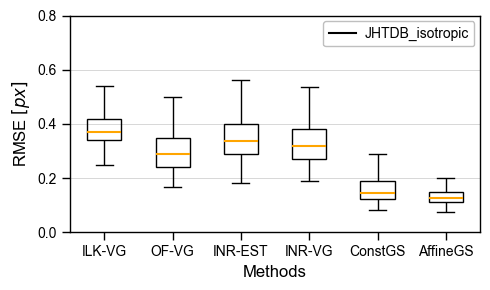

✅ 箱线图已保存：./output/EXP2/on_datasets/fig9-b.pdf


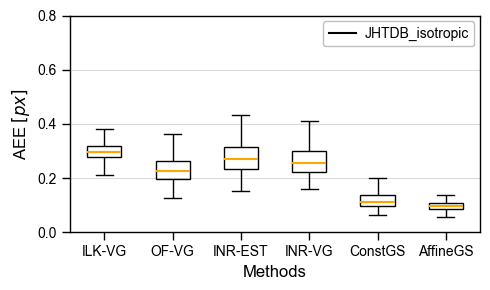

dataset:DNS_turbulence
✅ 箱线图已保存：./output/EXP2/on_datasets/fig9-c.pdf


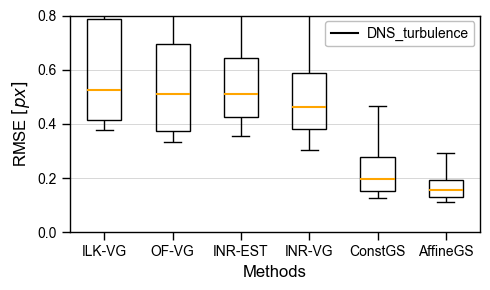

✅ 箱线图已保存：./output/EXP2/on_datasets/fig9-d.pdf


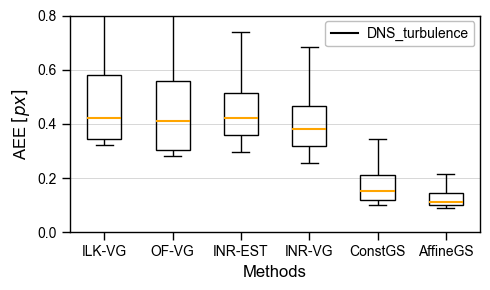

dataset:SQG
✅ 箱线图已保存：./output/EXP2/on_datasets/fig9-e.pdf


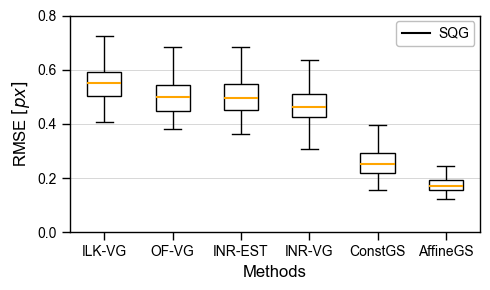

✅ 箱线图已保存：./output/EXP2/on_datasets/fig9-f.pdf


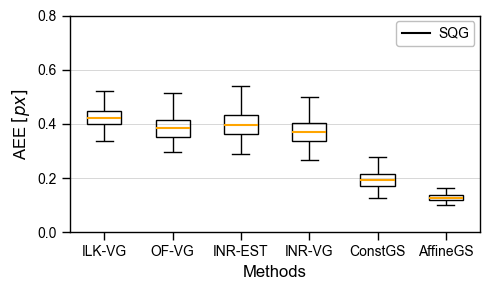

In [6]:
from utils.painter import plot_boxplot

datasets_name = ["JHTDB_isotropic", "DNS_turbulence", "SQG"]

def plot(data_index, datasets_name, use_Chinese = False, save=False):
    file_path = f"./output/EXP2/on_datasets/{datasets_name[data_index]}(1000).json"

    pdf_name = [["a", "b"], ["c", "d"], ["e", "f"]]
    
    if save is True:
        rmse_path = f"./output/EXP2/on_datasets/fig9-{pdf_name[data_index][0]}.pdf"
        aee_path = f"./output/EXP2/on_datasets/fig9-{pdf_name[data_index][1]}.pdf"
    else:
        rmse_path = None
        aee_path = None

    if use_Chinese is True:
        size = [18, 10]
    else:
        size = [12, 10]
        
    plot_boxplot(file_path, metric='rmse', save_path=rmse_path, 
        ylabel_en="RMSE $[px]$", ylabel_zh="RMSE $[px]$",
        xlabel_en='Methods', xlabel_zh='六种方法',
        title_en=None, title_zh=None,
        box_width=0.5, y_lim=(0, 0.8), 
        label_size=size[0], tick_size=size[1], 
        grid=True, use_chinese=use_Chinese, dataset_name=datasets_name[data_index]
    )
    
    plot_boxplot(file_path, metric='aee', save_path=aee_path, 
        ylabel_en="AEE $[px]$", ylabel_zh="AEE $[px]$",
        xlabel_en='Methods', xlabel_zh='六种方法',
        title_en=None, title_zh=None,
        box_width=0.5, y_lim=(0,0.8), 
        label_size=size[0], tick_size=size[1], 
        grid=True, use_chinese=use_Chinese, dataset_name=datasets_name[data_index]
    )

for data_index in range(3):
    print(f"dataset:{datasets_name[data_index]}")
    plot(data_index=data_index, datasets_name=datasets_name, use_Chinese = False, save=True)